# Assignment 2 - Part B: Breast Cancer Classification with 30 Features

This notebook follows `Class03f2_Breast-Cancer-Classification.ipynb` and completes Tasks a, b and c. It compares a one-hidden-layer ANN with a three-hidden-layer ANN using all 30 input features. Malignant cancer is defined as the positive class (`M = 1`), while benign cancer is `B = 0`.

In [1]:
import random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import tensorflow as tf
from sklearn.metrics import confusion_matrix, f1_score, precision_score, recall_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.models import Sequential
from tensorflow.keras.utils import to_categorical

SEED = 2
TEST_SIZE = 0.25
VALIDATION_SPLIT = 0.20
MAX_EPOCHS = 150
BATCH_SIZE = 32
PATIENCE = 15

random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)
print('TensorFlow version:', tf.__version__)

TensorFlow version: 2.21.0


## Load and inspect the Wisconsin breast cancer dataset

Upload `BCW_dataset.csv` when Colab requests it.

In [2]:
DATA_PATH = Path('BCW_dataset.csv')
if not DATA_PATH.exists():
    try:
        from google.colab import files
        print('Please upload BCW_dataset.csv')
        files.upload()
    except ImportError as exc:
        raise FileNotFoundError('Place BCW_dataset.csv in the notebook folder.') from exc

data_raw = pd.read_csv(DATA_PATH)
data_raw.head()

Please upload BCW_dataset.csv


Saving BCW_dataset.csv to BCW_dataset.csv


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


Input shape: (569, 30)
Class counts (0 = benign, 1 = malignant):
diagnosis
0    357
1    212
Name: count, dtype: int64


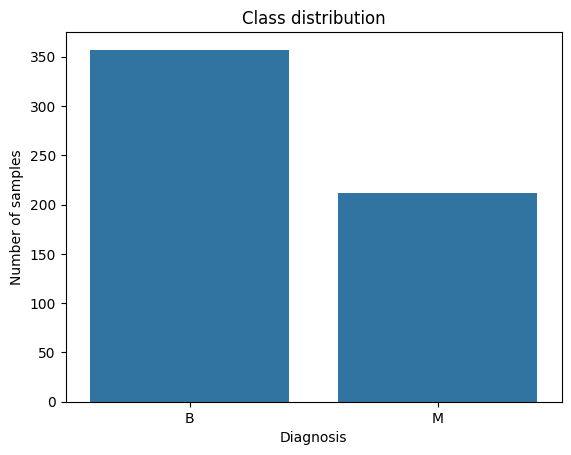

In [3]:
# Remove the ID, diagnosis and empty CSV column from the model inputs.
drop_columns = ['id', 'diagnosis'] + [c for c in data_raw.columns if c.startswith('Unnamed')]
X = data_raw.drop(columns=drop_columns)
y = data_raw['diagnosis'].map({'M': 1, 'B': 0}).astype('int32')

assert X.shape == (569, 30), f'Expected (569, 30), obtained {X.shape}'
assert not X.isna().any().any(), 'Input features contain missing values.'
assert not y.isna().any(), 'Diagnosis contains an unexpected label.'

print('Input shape:', X.shape)
print('Class counts (0 = benign, 1 = malignant):')
print(y.value_counts().sort_index())

sns.countplot(x=data_raw['diagnosis'], order=['B', 'M'])
plt.title('Class distribution')
plt.xlabel('Diagnosis')
plt.ylabel('Number of samples')
plt.show()

## Create the 75% training and 25% test sets

The split is stratified so that both sets retain approximately the same malignant/benign ratio. The scaler is fitted only on the training data to prevent test-data leakage.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=SEED, stratify=y
)

scaler = StandardScaler()
X_train_n = scaler.fit_transform(X_train)
X_test_n = scaler.transform(X_test)
Y_train = to_categorical(y_train, num_classes=2)
Y_test = to_categorical(y_test, num_classes=2)

print('Training inputs:', X_train_n.shape)
print('Test inputs:', X_test_n.shape)
print('Training outputs:', Y_train.shape)
print('Test outputs:', Y_test.shape)

Training inputs: (426, 30)
Test inputs: (143, 30)
Training outputs: (426, 2)
Test outputs: (143, 2)


## Define, train and evaluate the ANN models

Both networks use two softmax output units and categorical cross-entropy, as required by the assignment. The one-hidden-layer model uses 50 neurons. The three-hidden-layer model uses 64, 32 and 16 neurons.

In [5]:
def build_model(hidden_layers, number_of_features):
    model = Sequential()
    model.add(Input(shape=(number_of_features,)))
    for neurons in hidden_layers:
        model.add(Dense(neurons, activation='relu'))
    model.add(Dense(2, activation='softmax'))
    model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    return model

def train_and_evaluate(model_name, hidden_layers):
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)
    model = build_model(hidden_layers, X_train_n.shape[1])
    early_stopping = tf.keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=PATIENCE, restore_best_weights=True
    )
    history = model.fit(
        X_train_n, Y_train,
        validation_split=VALIDATION_SPLIT,
        epochs=MAX_EPOCHS, batch_size=BATCH_SIZE,
        shuffle=True, callbacks=[early_stopping], verbose=0
    )

    test_loss, test_accuracy = model.evaluate(X_test_n, Y_test, verbose=0)
    probabilities = model.predict(X_test_n, verbose=0)
    predictions = np.argmax(probabilities, axis=1)
    matrix = confusion_matrix(y_test, predictions, labels=[0, 1])

    result = {
        'features': 30,
        'model': model_name,
        'hidden_layers': '-'.join(map(str, hidden_layers)),
        'parameters': model.count_params(),
        'epochs_trained': len(history.history['loss']),
        'test_accuracy': test_accuracy,
        'test_loss': test_loss,
        'precision_M': precision_score(y_test, predictions, pos_label=1, zero_division=0),
        'recall_M': recall_score(y_test, predictions, pos_label=1, zero_division=0),
        'f1_M': f1_score(y_test, predictions, pos_label=1, zero_division=0)
    }
    return model, history, matrix, result

model_configurations = {
    'One hidden layer': (50,),
    'Three hidden layers': (64, 32, 16)
}

trained_models = {}
histories = {}
confusion_matrices = {}
results = []

for model_name, hidden_layers in model_configurations.items():
    model, history, matrix, result = train_and_evaluate(model_name, hidden_layers)
    trained_models[model_name] = model
    histories[model_name] = history
    confusion_matrices[model_name] = matrix
    results.append(result)

results_30 = pd.DataFrame(results)
results_30.style.format({
    'test_accuracy': '{:.4f}', 'test_loss': '{:.4f}',
    'precision_M': '{:.4f}', 'recall_M': '{:.4f}', 'f1_M': '{:.4f}'
})

,features,model,hidden_layers,parameters,epochs_trained,test_accuracy,test_loss,precision_M,recall_M,f1_M
0,30,One hidden layer,50,1652,46,0.9580,0.1414,0.9434,0.9434,0.9434
1,30,Three hidden layers,64-32-16,4626,24,0.9580,0.1265,0.9434,0.9434,0.9434


## Confusion matrices and learning curves

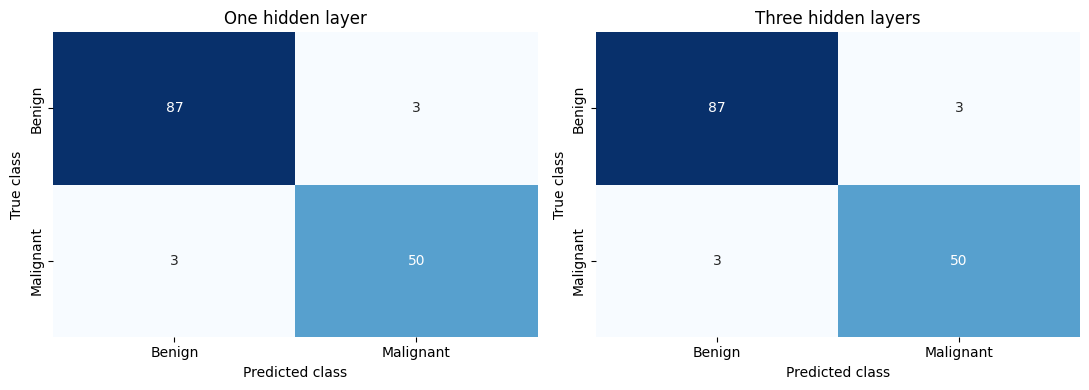

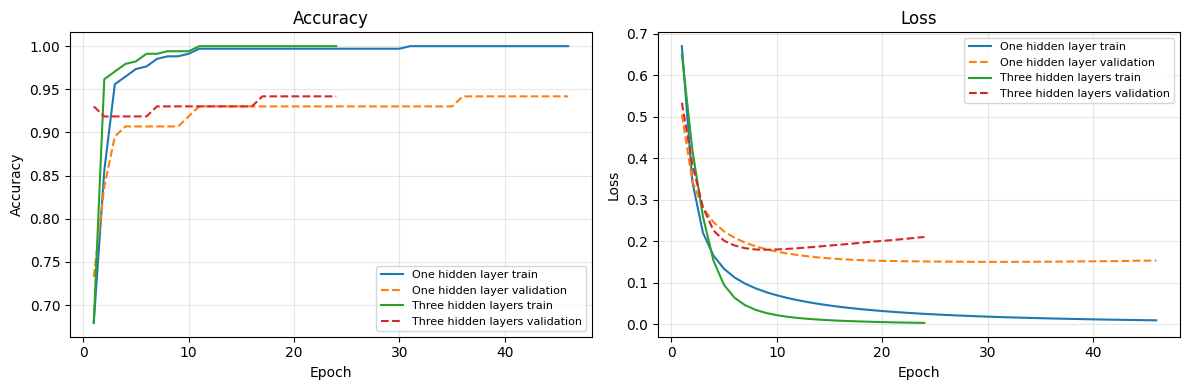

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (model_name, matrix) in zip(axes, confusion_matrices.items()):
    sns.heatmap(matrix, annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=['Benign', 'Malignant'],
                yticklabels=['Benign', 'Malignant'], ax=ax)
    ax.set_title(model_name)
    ax.set_xlabel('Predicted class')
    ax.set_ylabel('True class')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for model_name, history in histories.items():
    epochs = range(1, len(history.history['loss']) + 1)
    axes[0].plot(epochs, history.history['accuracy'], label=model_name + ' train')
    axes[0].plot(epochs, history.history['val_accuracy'], '--', label=model_name + ' validation')
    axes[1].plot(epochs, history.history['loss'], label=model_name + ' train')
    axes[1].plot(epochs, history.history['val_loss'], '--', label=model_name + ' validation')
axes[0].set(title='Accuracy', xlabel='Epoch', ylabel='Accuracy')
axes[1].set(title='Loss', xlabel='Epoch', ylabel='Loss')
for ax in axes:
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## Parameter count and accuracy comparison

,features,model,hidden_layers,parameters,epochs_trained,test_accuracy,test_loss,precision_M,recall_M,f1_M
0,30,One hidden layer,50,1652,46,0.9580,0.1414,0.9434,0.9434,0.9434
1,30,Three hidden layers,64-32-16,4626,24,0.9580,0.1265,0.9434,0.9434,0.9434


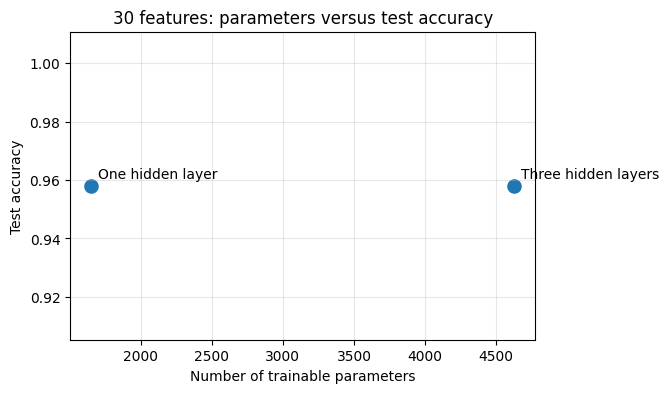

Saved PartB_30_features_results.csv


In [7]:
display(results_30.style.format({
    'test_accuracy': '{:.4f}', 'test_loss': '{:.4f}',
    'precision_M': '{:.4f}', 'recall_M': '{:.4f}', 'f1_M': '{:.4f}'
}).background_gradient(subset=['test_accuracy'], cmap='Greens'))

plt.figure(figsize=(6, 4))
plt.scatter(results_30['parameters'], results_30['test_accuracy'], s=90)
for _, row in results_30.iterrows():
    plt.annotate(row['model'], (row['parameters'], row['test_accuracy']),
                 xytext=(5, 5), textcoords='offset points')
plt.xlabel('Number of trainable parameters')
plt.ylabel('Test accuracy')
plt.title('30 features: parameters versus test accuracy')
plt.grid(alpha=0.3)
plt.show()

results_30.to_csv('PartB_30_features_results.csv', index=False)
print('Saved PartB_30_features_results.csv')